# NF-UNSW-NB15-v3 — Data understanding

**Owner:** Ahmed Hamouda  
**Goal of this notebook:** understand the dataset and find its quality problems. For each problem we
take a decision on how it will be solved. The data is **not changed** here: the solutions are applied
later, once the team has agreed on them.

## Step 0 — Initial inspection *(lab 2.1)*
- Load the dataset and describe its structure
- Data type of each column
- Number of rows and columns
- Obvious quality issues from the first look

### 0.1 Load the data

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *

pd.set_option("display.max_columns", 100)

SOURCE = "UNSW"
path = RAW_DIR / DATASETS[SOURCE]["file"]
df = pd.read_csv(path)

print("rows:", len(df))
print("columns:", df.shape[1])

rows: 2365424
columns: 55


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2365424 entries, 0 to 2365423
Data columns (total 55 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   FLOW_START_MILLISECONDS      int64  
 1   FLOW_END_MILLISECONDS        int64  
 2   IPV4_SRC_ADDR                str    
 3   L4_SRC_PORT                  int64  
 4   IPV4_DST_ADDR                str    
 5   L4_DST_PORT                  int64  
 6   PROTOCOL                     int64  
 7   L7_PROTO                     float64
 8   IN_BYTES                     int64  
 9   IN_PKTS                      int64  
 10  OUT_BYTES                    int64  
 11  OUT_PKTS                     int64  
 12  TCP_FLAGS                    int64  
 13  CLIENT_TCP_FLAGS             int64  
 14  SERVER_TCP_FLAGS             int64  
 15  FLOW_DURATION_MILLISECONDS   int64  
 16  DURATION_IN                  int64  
 17  DURATION_OUT                 int64  
 18  MIN_TTL                      int64  
 19  MAX_TTL    

### 0.2 What the data looks like
The first flows, then summary statistics for every numeric column.

In [3]:
df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1424242193040,1424242193043,59.166.0.2,4894,149.171.126.3,53,17,5.0,146,2,178,2,0,0,0,2,0,0,31,31,89,73,73,89,89.000000,73.000000,0,0,0,0,389333,474666,4,0,0,0,0,0,0,0,0,46779,1,60,0,0,0,0,0,0,0,0,0,0,Benign
1,1424242192744,1424242193079,59.166.0.4,52671,149.171.126.6,31992,6,11.0,4704,28,2976,28,27,27,27,335,334,334,31,32,984,52,52,984,8.883582,14.041791,1988,7,1068,6,112000,70857,34,18,2,2,0,14480,14480,50176,196,0,0,0,0,0,91,12,19,0,90,12,19,0,Benign
2,1424242190649,1424242193109,59.166.0.0,47290,149.171.126.9,6881,6,37.0,13662,238,548216,438,27,27,27,2460,2459,2459,31,32,1500,52,52,1500,222.852033,5.553659,1735,21,272908,196,44411,1782091,288,0,4,32,352,65160,34752,50944,199,0,0,0,0,0,1843,10,119,0,1843,5,88,0,Benign
3,1424242193145,1424242193146,59.166.0.8,43310,149.171.126.7,53,17,5.0,146,2,178,2,0,0,0,1,0,0,31,31,89,73,73,89,178.000000,146.000000,0,0,0,0,584000,712000,4,0,0,0,0,0,0,0,0,3211,1,60,0,0,0,0,0,0,0,0,0,0,Benign
4,1424242193239,1424242193241,59.166.0.1,45870,149.171.126.1,53,17,5.0,130,2,162,2,0,0,0,1,0,0,31,31,81,65,65,81,162.000000,130.000000,0,0,0,0,520000,648000,4,0,0,0,0,0,0,0,0,5771,1,60,0,0,0,0,0,0,0,0,0,0,Benign


In [4]:
df.describe().T

c:\Users\hamou\Desktop\ME\Computer Systeam\Final\S1\Data Science\LAB\DS_Project\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\hamou\Desktop\ME\Computer Systeam\Final\S1\Data Science\LAB\DS_Project\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
FLOW_START_MILLISECONDS,2365424.0,1.423141e+12,1.144853e+09,1.421927e+12,1.421951e+12,1.424221e+12,1.424242e+12,1.424263e+12
FLOW_END_MILLISECONDS,2365424.0,1.423141e+12,1.144853e+09,1.421927e+12,1.421951e+12,1.424221e+12,1.424242e+12,1.424263e+12
L4_SRC_PORT,2365424.0,3.266052e+04,1.915897e+04,0.000000e+00,1.592700e+04,3.281500e+04,4.910000e+04,6.553500e+04
L4_DST_PORT,2365424.0,1.114841e+04,1.839424e+04,0.000000e+00,2.500000e+01,8.000000e+01,1.462925e+04,6.553500e+04
PROTOCOL,2365424.0,8.730817e+00,6.384764e+00,0.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,2.550000e+02
L7_PROTO,2365424.0,2.353191e+01,2.126820e+01,0.000000e+00,5.000000e+00,3.600000e+01,3.700000e+01,4.210000e+02
IN_BYTES,2365424.0,4.413591e+03,6.769945e+04,1.000000e+00,4.810000e+02,1.580000e+03,3.048000e+03,2.702093e+07
IN_PKTS,2365424.0,3.528169e+01,7.839349e+01,1.000000e+00,4.000000e+00,1.600000e+01,4.400000e+01,2.016600e+04
OUT_BYTES,2365424.0,3.432003e+04,1.550732e+05,0.000000e+00,3.120000e+02,2.456000e+03,1.437000e+04,1.465675e+07
OUT_PKTS,2365424.0,4.471138e+01,1.163444e+02,0.000000e+00,4.000000e+00,1.800000e+01,4.200000e+01,1.102400e+04


### 0.3 Feature dictionary
Every column with its official description (from `NetFlow_v3_Features.csv`), type, number of distinct values and an example value.

In [5]:
features = pd.read_csv(RAW_DIR / "NetFlow_v3_Features.csv")
features["Feature"] = features["Feature"].str.strip()

dictionary = pd.DataFrame({
    "description": df.columns.map(features.set_index("Feature")["Description"]),
    "dtype": df.dtypes.astype(str).values,
    "distinct": df.nunique().values,
    "example": df.iloc[0].values,
}, index=df.columns)
dictionary

,description,dtype,distinct,example
FLOW_START_MILLISECONDS,Flow start timestamp in milliseconds,int64,1893404,1424242193040
FLOW_END_MILLISECONDS,Flow end timestamp in milliseconds,int64,2299732,1424242193043
IPV4_SRC_ADDR,IPv4 source address,str,40,59.166.0.2
L4_SRC_PORT,IPv4 source port number,int64,64597,4894
IPV4_DST_ADDR,IPv4 destination address,str,40,149.171.126.3
L4_DST_PORT,IPv4 destination port number,int64,64617,53
PROTOCOL,IP protocol identifier byte,int64,255,17
L7_PROTO,Layer 7 protocol (numeric),float64,141,5.0
IN_BYTES,Incoming number of bytes,int64,13658,146
IN_PKTS,Incoming number of packets,int64,892,2


## Step 1 — Target columns (`Label`, `Attack`)
Checked first because the later checks (duplicates, missing values, outliers) are done per attack class.
If the labels are wrong, every per-class result is wrong too.

### 1.1 Label spellings
`repr` shows hidden spaces or unusual characters around each label.

In [6]:
labels = sorted(df["Attack"].unique())
print("number of labels:", len(labels))
for label in labels:
    print(repr(label))

number of labels: 10
'Analysis'
'Backdoor'
'Benign'
'DoS'
'Exploits'
'Fuzzers'
'Generic'
'Reconnaissance'
'Shellcode'
'Worms'


### 1.2 Does `Label` (0/1) agree with `Attack`?
Every `Benign` flow must have `Label = 0`, and every attack must have `Label = 1`.

In [7]:
pd.crosstab(df["Attack"], df["Label"], margins=True)

Label,0,1,All
Attack,,,
Analysis,0,1226,1226
Backdoor,0,4659,4659
Benign,2237731,0,2237731
DoS,0,5980,5980
Exploits,0,42748,42748
Fuzzers,0,33816,33816
Generic,0,19651,19651
Reconnaissance,0,17074,17074
Shellcode,0,2381,2381


In [8]:
is_benign = df["Attack"] == "Benign"
disagree = (is_benign & (df["Label"] == 1)) | (~is_benign & (df["Label"] == 0))
print("rows where Label and Attack disagree:", disagree.sum())

rows where Label and Attack disagree: 0


### 1.3 Are all labels in the team taxonomy?
`map_labels` (from `src/config.py`) stops with an error if a label is missing from the shared taxonomy.

In [9]:
mapped = map_labels(df[["Attack"]], "Attack", SOURCE)
mapped.drop_duplicates().sort_values(["attack_family", "attack_label"]).reset_index(drop=True)

,Attack,source_dataset,attack_label,attack_family,is_attack
0,Benign,UNSW,Benign,Benign,0
1,DoS,UNSW,DoS,Denial of service,1
2,Exploits,UNSW,Exploits,Exploitation and intrusion,1
3,Shellcode,UNSW,Shellcode,Exploitation and intrusion,1
4,Fuzzers,UNSW,Fuzzers,Fuzzing and crypto,1
5,Generic,UNSW,Generic,Fuzzing and crypto,1
6,Backdoor,UNSW,Backdoor,Malware and botnets,1
7,Worms,UNSW,Worms,Malware and botnets,1
8,Analysis,UNSW,Analysis,Reconnaissance,1
9,Reconnaissance,UNSW,Reconnaissance,Reconnaissance,1


### 1.4 Class distribution

In [10]:
distribution = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "percent": (100 * df["Attack"].value_counts(normalize=True)).round(3),
})
distribution

,flows,percent
Attack,,
Benign,2237731,94.602
Exploits,42748,1.807
Fuzzers,33816,1.430
Generic,19651,0.831
Reconnaissance,17074,0.722
DoS,5980,0.253
Backdoor,4659,0.197
Shellcode,2381,0.101
Analysis,1226,0.052


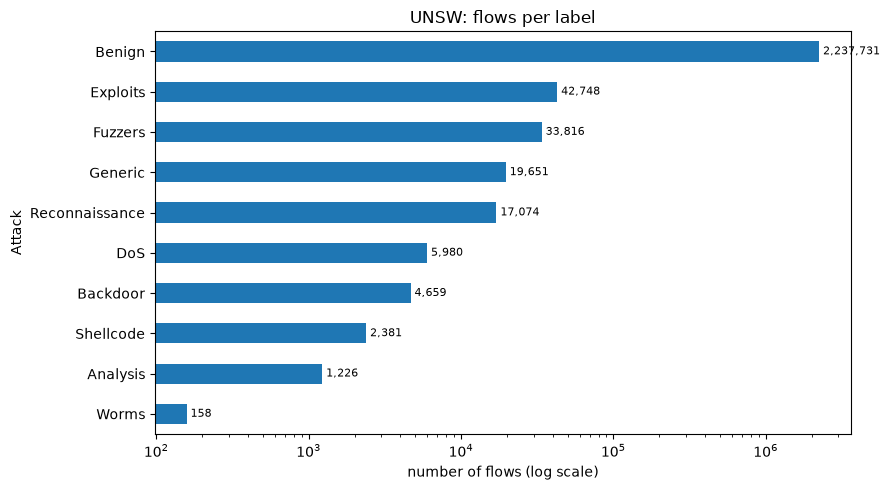

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
distribution["flows"].sort_values().plot.barh(ax=ax)
ax.set_xscale("log")
ax.set_xlabel("number of flows (log scale)")
ax.set_title("UNSW: flows per label")
for i, v in enumerate(distribution["flows"].sort_values()):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### Step 1 — Findings
- **Labels are clean:** 10 labels, no hidden spaces or inconsistent spellings, and `Label` agrees with `Attack` on all 2,365,424 rows.
- **All labels are in the team taxonomy**, covering 6 of the 9 families. Credential attacks, Web and injection, Interception and spoofing, and Data theft are not present in UNSW.
- **Strong class imbalance:** Benign is 94.6% of the flows (17.5 benign flows per attack flow).
- **Worms is very rare:** 158 flows (0.007%).

## Step 2 — Data types and codes *(lab 2.3)*
- Columns that should be numeric but are stored as text
- Timestamps stored as integers
- Codes stored as numbers, and invalid codes
- Proposed solution for each issue

### 2.1 Columns stored as text
Are there text columns that actually contain numbers?

In [12]:
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    as_number = pd.to_numeric(df[col], errors="coerce")
    print(f"{col:15s} distinct: {df[col].nunique():>9,}   values that are numbers: {as_number.notna().sum():,}")

IPV4_SRC_ADDR   distinct:        40   values that are numbers: 0
IPV4_DST_ADDR   distinct:        40   values that are numbers: 0
Attack          distinct:        10   values that are numbers: 0


### 2.2 Timestamps stored as integers
`FLOW_START_MILLISECONDS` and `FLOW_END_MILLISECONDS` are milliseconds since 1 January 1970. Converted here only to check that the dates are plausible.

In [13]:
start = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")
end = pd.to_datetime(df["FLOW_END_MILLISECONDS"], unit="ms")
print("first flow starts:", start.min())
print("last flow ends:   ", end.max())

first flow starts: 2015-01-22 11:49:36.907000
last flow ends:    2015-02-18 12:29:25.011000


In [14]:
# Flows per capture day
start.dt.date.value_counts().sort_index()

FLOW_START_MILLISECONDS
2015-01-22    1095574
2015-01-23      39778
2015-02-18    1230072
Name: count, dtype: int64

### 2.3 Codes stored as numbers
These columns hold identifiers of a protocol, port, flag or message type. Their numbers have no order or size: an average port or protocol has no meaning.

In [15]:
code_cols = ["L4_SRC_PORT", "L4_DST_PORT", "PROTOCOL", "L7_PROTO",
             "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
             "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"]

pd.DataFrame({
    "dtype": df[code_cols].dtypes.astype(str),
    "distinct values": df[code_cols].nunique(),
    "most common": [df[c].mode()[0] for c in code_cols],
})

,dtype,distinct values,most common
L4_SRC_PORT,int64,64597,1043.0
L4_DST_PORT,int64,64617,21.0
PROTOCOL,int64,255,6.0
L7_PROTO,float64,141,37.0
TCP_FLAGS,int64,14,27.0
CLIENT_TCP_FLAGS,int64,14,27.0
SERVER_TCP_FLAGS,int64,14,27.0
ICMP_TYPE,int64,1188,0.0
ICMP_IPV4_TYPE,int64,256,0.0
DNS_QUERY_TYPE,int64,20,0.0


### 2.4 `L7_PROTO` stored as a float
A value like `7.37` is two codes in one: the outer protocol (7 = HTTP) and the application inside it (37 = BitTorrent).

In [16]:
has_decimals = df["L7_PROTO"] % 1 != 0
print(f"flows with a decimal L7_PROTO: {has_decimals.sum():,} ({100 * has_decimals.mean():.2f} %)")
df.loc[has_decimals, "L7_PROTO"].value_counts()

flows with a decimal L7_PROTO: 23,866 (1.01 %)


L7_PROTO
7.370     18765
10.160     4877
7.253       146
7.376        45
7.500         8
7.212         7
10.410        7
7.291         7
7.126         2
7.180         2
Name: count, dtype: int64

### 2.5 Invalid codes
Codes that do not exist in the official lists:
- **Protocol numbers:** IANA has assigned 0–147; 148–252 are unassigned, 253–254 are for experiments and 255 is reserved.
- **Port 0:** reserved and never used by real TCP/UDP traffic. Other protocols have no ports, so 0 is normal there.
- **DNS query types:** only the types assigned by IANA are valid.
- **ICMP types:** only the types assigned by IANA are valid. Checked on ICMP flows only.

In [17]:
unassigned_proto = df["PROTOCOL"] > 147
print(f"flows with an unassigned protocol number: {unassigned_proto.sum():,}")
print(f"distinct unassigned protocol numbers:     {df.loc[unassigned_proto, 'PROTOCOL'].nunique()}")
df.loc[unassigned_proto, "Attack"].value_counts()

flows with an unassigned protocol number: 754
distinct unassigned protocol numbers:     108


Attack
Fuzzers           620
Exploits           67
Reconnaissance     48
Generic            18
DoS                 1
Name: count, dtype: int64

In [18]:
tcp_udp = df["PROTOCOL"].isin([6, 17])
port0 = tcp_udp & ((df["L4_SRC_PORT"] == 0) | (df["L4_DST_PORT"] == 0))
print(f"TCP/UDP flows using port 0: {port0.sum():,}")
df.loc[port0, "Attack"].value_counts()

TCP/UDP flows using port 0: 6


Attack
Reconnaissance    2
Exploits          2
Generic           1
Backdoor          1
Name: count, dtype: int64

In [19]:
# IANA DNS record types: 1-260 are the standard range, 32768-32769 are DNSSEC-related
dns = df["DNS_QUERY_TYPE"]
invalid_dns = (dns != 0) & ~(dns.between(1, 260) | dns.isin([32768, 32769]))
print(f"flows with an invalid DNS query type: {invalid_dns.sum()}")
df.loc[invalid_dns, ["L4_DST_PORT", "DNS_QUERY_TYPE", "Attack"]]

flows with an invalid DNS query type: 6


,L4_DST_PORT,DNS_QUERY_TYPE,Attack
7344,53,55937,DoS
95125,53,13226,DoS
159304,53,3282,DoS
337699,53,45976,DoS
743718,53,24268,DoS
1329834,53,36477,DoS


In [20]:
# IANA ICMP types still in use
valid_icmp = [0, 3, 4, 5, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 30, 40, 41, 42, 43]
icmp = df["PROTOCOL"] == 1
invalid_icmp = icmp & ~df["ICMP_IPV4_TYPE"].isin(valid_icmp)
print(f"ICMP flows: {icmp.sum()}, with an invalid ICMP type: {invalid_icmp.sum()}")
df.loc[invalid_icmp, ["ICMP_TYPE", "ICMP_IPV4_TYPE", "Attack"]].value_counts()

ICMP flows: 401, with an invalid ICMP type: 6


ICMP_TYPE  ICMP_IPV4_TYPE  Attack        
16976      66              Reconnaissance    2
                           Shellcode         2
                           Generic           2
Name: count, dtype: int64

### Step 2 — Findings
- **No numbers hidden in text:** the only text columns are the two IP addresses and `Attack`. There are only **40 distinct IP addresses** (see Step 7).
- **Timestamps** are integers (milliseconds since 1970). Converted, they cover 3 capture days: 22 Jan, 23 Jan and 18 Feb 2015.
- **11 code columns are stored as numbers:** ports, `PROTOCOL`, `L7_PROTO`, TCP flags, ICMP type, DNS query type and FTP return code.
- **`L7_PROTO` is a float that holds two codes** (`7.37` = HTTP carrying BitTorrent) for 23,866 flows. The raw CSV already lost trailing zeros, so 10 flows (`7.5`, `7.18`) are ambiguous.
- **Invalid codes appear only in attack traffic:**
  - 754 flows with an unassigned protocol number, 620 of them Fuzzers;
  - 6 TCP/UDP flows on port 0;
  - 6 invalid DNS query types (all DoS);
  - 6 invalid ICMP types.
  These are attack behaviour, not recording errors.

## Step 3 — Missing values *(lab 2.2)*
- Real missing values (NaN), count and percentage
- Infinite values and their cause
- Disguised missing values (0 = not applicable)
- Visualisation of the missing values
- Strategy for each type of missing value

### 3.1 Real missing values (NaN)

In [21]:
nan_count = df.isna().sum()
pd.DataFrame({"missing": nan_count, "percent": (100 * nan_count / len(df)).round(3)})[nan_count > 0]

,missing,percent
SRC_TO_DST_SECOND_BYTES,63425,2.681


### 3.2 Infinite values

In [22]:
numeric = df.select_dtypes("number")
inf_count = np.isinf(numeric).sum()
pd.DataFrame({"infinite": inf_count, "percent": (100 * inf_count / len(df)).round(3)})[inf_count > 0]

,infinite,percent
SRC_TO_DST_SECOND_BYTES,59068,2.497
DST_TO_SRC_SECOND_BYTES,122493,5.178


### 3.3 Where do the NaN and inf come from?
The two `..._SECOND_BYTES` columns are a division by the flow duration, so a duration of 0 is the first suspect.
We also check which byte column each one is actually computed from.

In [23]:
zero_duration = df["FLOW_DURATION_MILLISECONDS"] == 0
s2d, d2s = df["SRC_TO_DST_SECOND_BYTES"], df["DST_TO_SRC_SECOND_BYTES"]

print(f"flows with duration 0: {zero_duration.sum():,}")
pd.DataFrame({
    "duration = 0": [s2d[zero_duration].isna().sum(), np.isinf(s2d[zero_duration]).sum(), np.isinf(d2s[zero_duration]).sum()],
    "duration > 0": [s2d[~zero_duration].isna().sum(), np.isinf(s2d[~zero_duration]).sum(), np.isinf(d2s[~zero_duration]).sum()],
}, index=["SRC_TO_DST_SECOND_BYTES NaN", "SRC_TO_DST_SECOND_BYTES inf", "DST_TO_SRC_SECOND_BYTES inf"])

flows with duration 0: 122,493


,duration = 0,duration > 0
SRC_TO_DST_SECOND_BYTES NaN,63425,0
SRC_TO_DST_SECOND_BYTES inf,59068,0
DST_TO_SRC_SECOND_BYTES inf,122493,0


In [24]:
# Which formula reproduces each column? (share of flows with duration > 0 that match)
ok = ~zero_duration
duration_ms = df.loc[ok, "FLOW_DURATION_MILLISECONDS"]
formulas = pd.DataFrame({
    col: {
        "IN_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "OUT_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "OUT_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "IN_BYTES / duration (s)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / (duration_ms / 1000), rtol=1e-3).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
})
(100 * formulas).round(2)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
IN_BYTES / duration (ms),0.01,100.00
OUT_BYTES / duration (ms),100.00,0.01
IN_BYTES / duration (s),0.00,0.00


In [25]:
# NaN rows: what do they have in common?
df.loc[s2d.isna(), ["IN_PKTS", "OUT_PKTS", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS"]].describe().loc[["min", "max"]]

,IN_PKTS,OUT_PKTS,OUT_BYTES,FLOW_DURATION_MILLISECONDS
min,1.0,0.0,0.0,0.0
max,6.0,0.0,0.0,0.0


### 3.4 Is the missingness linked to the attack class?

In [26]:
missing_by_class = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "NaN or inf (%)": (100 * (s2d.isna() | np.isinf(s2d) | np.isinf(d2s)).groupby(df["Attack"]).mean()).round(2),
}).sort_values("NaN or inf (%)", ascending=False)
missing_by_class

,flows,NaN or inf (%)
Attack,,
Generic,19651,75.78
Reconnaissance,17074,33.87
Shellcode,2381,33.39
Backdoor,4659,25.93
Fuzzers,33816,24.33
DoS,5980,15.55
Worms,158,13.92
Exploits,42748,9.20
Benign,2237731,3.87


### 3.5 Visualisation

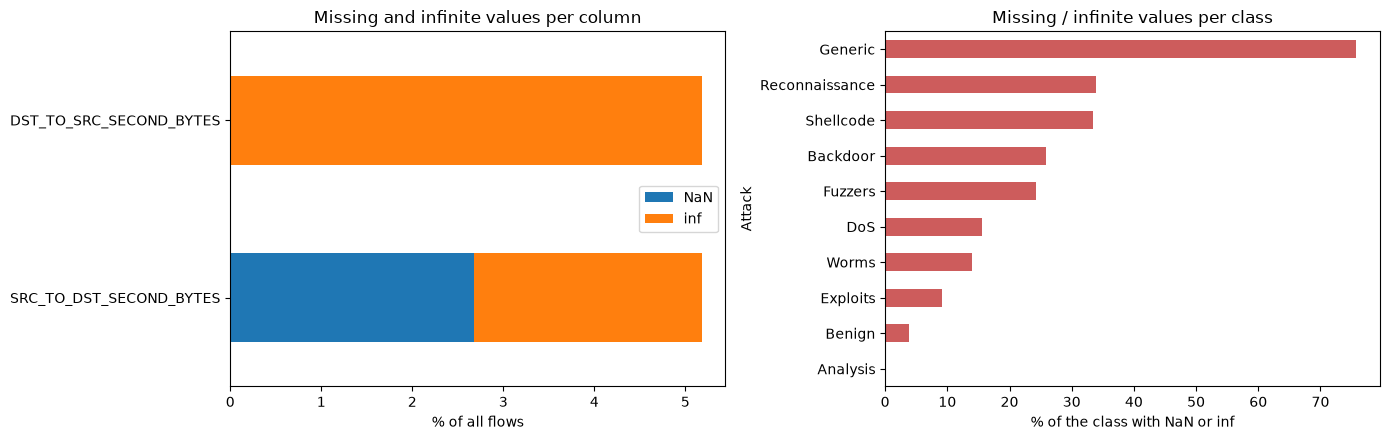

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pd.DataFrame({
    "NaN": 100 * df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]].isna().mean(),
    "inf": 100 * np.isinf(df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]]).mean(),
}).plot.barh(stacked=True, ax=axes[0])
axes[0].set_xlabel("% of all flows")
axes[0].set_title("Missing and infinite values per column")

missing_by_class["NaN or inf (%)"].sort_values().plot.barh(ax=axes[1], color="indianred")
axes[1].set_xlabel("% of the class with NaN or inf")
axes[1].set_title("Missing / infinite values per class")
plt.tight_layout()
plt.show()

### 3.6 Disguised missing values
A value of 0 can mean "does not apply" (no DNS query in a web flow) or "not recorded". Each protocol-specific
field should only be filled for its own protocol.

In [28]:
is_dns = (df["L4_DST_PORT"] == 53) | (df["L4_SRC_PORT"] == 53) | (df["L7_PROTO"].astype(int) == 5)
is_ftp = (df["L4_DST_PORT"] == 21) | (df["L4_SRC_PORT"] == 21) | (df["L7_PROTO"].astype(int) == 1)
is_icmp = df["PROTOCOL"] == 1
is_tcp = df["PROTOCOL"] == 6

pd.DataFrame([
    ["DNS_QUERY_TYPE", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_QUERY_TYPE"] == 0)).sum(), (~is_dns & (df["DNS_QUERY_TYPE"] != 0)).sum()],
    ["DNS_TTL_ANSWER", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_TTL_ANSWER"] == 0)).sum(), (~is_dns & (df["DNS_TTL_ANSWER"] != 0)).sum()],
    ["FTP_COMMAND_RET_CODE", "FTP flows", is_ftp.sum(), (is_ftp & (df["FTP_COMMAND_RET_CODE"] == 0)).sum(), (~is_ftp & (df["FTP_COMMAND_RET_CODE"] != 0)).sum()],
    ["ICMP_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_TYPE"] != 0)).sum()],
    ["ICMP_IPV4_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_IPV4_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_IPV4_TYPE"] != 0)).sum()],
    ["TCP_FLAGS", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_FLAGS"] == 0)).sum(), (~is_tcp & (df["TCP_FLAGS"] != 0)).sum()],
    ["TCP_WIN_MAX_IN", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_WIN_MAX_IN"] == 0)).sum(), (~is_tcp & (df["TCP_WIN_MAX_IN"] != 0)).sum()],
], columns=["column", "applies to", "flows it applies to", "0 where it applies", "filled where it does NOT apply"])

,column,applies to,flows it applies to,0 where it applies,filled where it does NOT apply
0,DNS_QUERY_TYPE,DNS flows,380634,112,0
1,DNS_TTL_ANSWER,DNS flows,380634,13994,0
2,FTP_COMMAND_RET_CODE,FTP flows,484037,43911,0
3,ICMP_TYPE,ICMP flows,401,6,1754341
4,ICMP_IPV4_TYPE,ICMP flows,401,6,1754337
5,TCP_FLAGS,TCP flows,1805270,7,0
6,TCP_WIN_MAX_IN,TCP flows,1805270,45833,0


In [29]:
# Which protocol carries the ICMP values that should not be there?
df.loc[~is_icmp & (df["ICMP_TYPE"] != 0), "PROTOCOL"].value_counts()

PROTOCOL
6    1754341
Name: count, dtype: int64

In [30]:
# TTL = 0: a packet with TTL 0 is discarded by the network, so 0 means "not recorded"
ttl0 = df["MIN_TTL"] == 0
print(f"flows with MIN_TTL = 0: {ttl0.sum():,}   with MAX_TTL = 0: {(df['MAX_TTL'] == 0).sum():,}")
print("by protocol:", dict(df.loc[ttl0, "PROTOCOL"].value_counts().head(3)))
print("by class:   ", dict(df.loc[ttl0, "Attack"].value_counts()))

flows with MIN_TTL = 0: 27,147   with MAX_TTL = 0: 27,147
by protocol: {17: np.int64(27051), 6: np.int64(47), 1: np.int64(28)}
by class:    {'Benign': np.int64(26951), 'Fuzzers': np.int64(99), 'Exploits': np.int64(34), 'DoS': np.int64(23), 'Generic': np.int64(16), 'Backdoor': np.int64(13), 'Reconnaissance': np.int64(9), 'Shellcode': np.int64(2)}


### Step 3 — Findings
- **Real missing values:** 63,425 NaN (2.68%), only in `SRC_TO_DST_SECOND_BYTES`.
- **Infinite values:** 59,068 in `SRC_TO_DST_SECOND_BYTES` and 122,493 in `DST_TO_SRC_SECOND_BYTES`.
- **Cause:** all of them, and only them, come from the 122,493 flows with **duration 0** (a division by zero). The NaN are 0 ÷ 0: one-way flows with no reply bytes.
- **The two columns are mislabelled.** `SRC_TO_DST_SECOND_BYTES` = `OUT_BYTES` ÷ duration, so its direction is swapped. Both are in **bytes per millisecond**, not per second as documented.
- **The missingness depends strongly on the class:**
  - 75.8% of Generic, 33.9% of Reconnaissance and 33.4% of Shellcode flows are affected;
  - only 3.9% of Benign flows are.
  Deleting these rows would remove most of the Generic class.
- **Disguised missing values:**
  - The DNS and FTP fields are consistent: they are 0 exactly where they do not apply.
  - The **ICMP fields are filled for 1,754,341 TCP flows**, where they have no meaning.
  - 27,147 flows (99% UDP, 99% Benign) have **TTL = 0**, which means "not recorded".

## Step 4 — Logical consistency and impossible values *(lab 2.5)*
- Negative values, invalid ports, end before start
- Relations between columns (min ≤ max, retransmitted ≤ total, ...)
- Protocol-specific fields on the wrong protocol
- Implausible values

### 4.1 Shared team rules (`validate` from `src/config.py`)

In [31]:
shared = validate(df)
print("total violations:", shared["violations"].sum())
shared[shared["violations"] > 0] if shared["violations"].sum() else shared.head(3)

total violations: 0


,check,violations
0,negative values in IN_BYTES,0
1,negative values in IN_PKTS,0
2,negative values in OUT_BYTES,0


### 4.2 Extra rules between columns

In [32]:
size_bins = df[[c for c in df.columns if c.startswith("NUM_PKTS_")]].sum(axis=1)
rules = {
    "end time - start time differs from duration by more than 1 ms":
        ((df["FLOW_END_MILLISECONDS"] - df["FLOW_START_MILLISECONDS"]) - df["FLOW_DURATION_MILLISECONDS"]).abs() > 1,
    "DURATION_IN or DURATION_OUT longer than the flow":
        (df["DURATION_IN"] > df["FLOW_DURATION_MILLISECONDS"]) | (df["DURATION_OUT"] > df["FLOW_DURATION_MILLISECONDS"]),
    "SHORTEST_FLOW_PKT > LONGEST_FLOW_PKT": df["SHORTEST_FLOW_PKT"] > df["LONGEST_FLOW_PKT"],
    "MIN_TTL > MAX_TTL": df["MIN_TTL"] > df["MAX_TTL"],
    "MIN_IP_PKT_LEN = 0 (packet with no size)": df["MIN_IP_PKT_LEN"] == 0,
    "MIN_IP_PKT_LEN differs from SHORTEST_FLOW_PKT": df["MIN_IP_PKT_LEN"] != df["SHORTEST_FLOW_PKT"],
    "MAX_IP_PKT_LEN differs from LONGEST_FLOW_PKT": df["MAX_IP_PKT_LEN"] != df["LONGEST_FLOW_PKT"],
    "packet longer than 1514 bytes (Ethernet limit)": df["LONGEST_FLOW_PKT"] > 1514,
    "retransmitted bytes/packets > total": (df["RETRANSMITTED_IN_BYTES"] > df["IN_BYTES"]) | (df["RETRANSMITTED_OUT_BYTES"] > df["OUT_BYTES"])
        | (df["RETRANSMITTED_IN_PKTS"] > df["IN_PKTS"]) | (df["RETRANSMITTED_OUT_PKTS"] > df["OUT_PKTS"]),
    "IN_BYTES below 20 bytes per packet (smallest IP header)": df["IN_BYTES"] < 20 * df["IN_PKTS"],
    "size-bin counts differ from IN_PKTS + OUT_PKTS": size_bins != df["IN_PKTS"] + df["OUT_PKTS"],
    "inter-arrival MIN > MAX or AVG > MAX": (df["SRC_TO_DST_IAT_MIN"] > df["SRC_TO_DST_IAT_MAX"]) | (df["SRC_TO_DST_IAT_AVG"] > df["SRC_TO_DST_IAT_MAX"])
        | (df["DST_TO_SRC_IAT_MIN"] > df["DST_TO_SRC_IAT_MAX"]) | (df["DST_TO_SRC_IAT_AVG"] > df["DST_TO_SRC_IAT_MAX"]),
    "largest inter-arrival gap longer than the flow": df["SRC_TO_DST_IAT_MAX"] > df["FLOW_DURATION_MILLISECONDS"] + 1,
    "DNS_TTL_ANSWER above 2^31-1 (invalid, RFC 2181)": df["DNS_TTL_ANSWER"] > 2**31 - 1,
    "DNS_TTL_ANSWER above 7 days (allowed but implausible)": df["DNS_TTL_ANSWER"] > 7 * 24 * 3600,
    "TCP flow without any TCP flag": is_tcp & (df["TCP_FLAGS"] == 0),
}
rule_table = pd.DataFrame({
    "violations": {name: int(mask.sum()) for name, mask in rules.items()},
    "percent": {name: round(100 * mask.mean(), 3) for name, mask in rules.items()},
    "main classes": {name: dict(df.loc[mask, "Attack"].value_counts().head(3)) if mask.any() else "" for name, mask in rules.items()},
})
rule_table

,violations,percent,main classes
end time - start time differs from duration by more than 1 ms,0,0.000,
DURATION_IN or DURATION_OUT longer than the flow,0,0.000,
SHORTEST_FLOW_PKT > LONGEST_FLOW_PKT,0,0.000,
MIN_TTL > MAX_TTL,0,0.000,
MIN_IP_PKT_LEN = 0 (packet with no size),66121,2.795,"{'Benign': 29335, 'Generic': 15142, 'Fuzzers':..."
MIN_IP_PKT_LEN differs from SHORTEST_FLOW_PKT,66121,2.795,"{'Benign': 29335, 'Generic': 15142, 'Fuzzers':..."
MAX_IP_PKT_LEN differs from LONGEST_FLOW_PKT,0,0.000,
packet longer than 1514 bytes (Ethernet limit),0,0.000,
retransmitted bytes/packets > total,0,0.000,
IN_BYTES below 20 bytes per packet (smallest IP header),45540,1.925,"{'Benign': 42961, 'Exploits': 1231, 'Fuzzers':..."


### 4.3 A closer look at the violations

In [33]:
# MIN_IP_PKT_LEN = 0 happens exactly on the one-way flows (no reply packets)
zero_len = df["MIN_IP_PKT_LEN"] == 0
print(f"MIN_IP_PKT_LEN = 0: {zero_len.sum():,}   OUT_PKTS = 0: {(df['OUT_PKTS'] == 0).sum():,}   both: {(zero_len & (df['OUT_PKTS'] == 0)).sum():,}")

MIN_IP_PKT_LEN = 0: 66,121   OUT_PKTS = 0: 66,121   both: 66,121


In [34]:
# Flows whose recorded bytes are too small for the number of packets
too_small = rules["IN_BYTES below 20 bytes per packet (smallest IP header)"]
print("protocols:", dict(df.loc[too_small, "PROTOCOL"].value_counts()))
df.loc[too_small, ["PROTOCOL", "IN_PKTS", "IN_BYTES", "SHORTEST_FLOW_PKT", "Attack"]].head()

protocols: {6: np.int64(45540)}


,PROTOCOL,IN_PKTS,IN_BYTES,SHORTEST_FLOW_PKT,Attack
173,6,1,9,52,Benign
180,6,1,9,40,Fuzzers
182,6,1,9,52,Benign
195,6,1,9,48,Fuzzers
197,6,1,9,52,Benign


In [35]:
# How far do the size-bin counts differ from the packet counts?
(size_bins - df["IN_PKTS"] - df["OUT_PKTS"]).value_counts().sort_index()

0     1882632
1         174
2          19
3          42
4          37
5         420
6          11
7         275
8          29
9       12446
10         47
11     469289
13          3
Name: count, dtype: int64

### 4.4 Extra rules from the ToN-IoT review
Four rules found by Cyrine Chabbar while checking NF-ToN-IoT-v3, now checked on every NetFlow dataset:
- **IAT average below IAT minimum:** an average gap between packets cannot be smaller than the smallest gap.
- **TCP window 0 although packets were sent in that direction:** possibly "not recorded" disguised as 0, like TTL = 0.
- **`OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0:** exceptions to the one-way-flow pattern of 4.3.
- **One-way single-packet flow whose packet is longer than `IN_BYTES`:** the packet cannot be longer than the whole flow.

In [ ]:
tcp = df["PROTOCOL"] == 6
extra = {
    "IAT average below IAT minimum (either direction)":
        (df["SRC_TO_DST_IAT_AVG"] < df["SRC_TO_DST_IAT_MIN"]) | (df["DST_TO_SRC_IAT_AVG"] < df["DST_TO_SRC_IAT_MIN"]),
    "TCP window 0 although packets were sent in that direction":
        tcp & (((df["IN_PKTS"] > 0) & (df["TCP_WIN_MAX_IN"] == 0)) | ((df["OUT_PKTS"] > 0) & (df["TCP_WIN_MAX_OUT"] == 0))),
    "OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0":
        (df["OUT_PKTS"] == 0) & (df["MIN_IP_PKT_LEN"] > 0),
    "one-way single-packet flow longer than IN_BYTES":
        (df["IN_PKTS"] == 1) & (df["OUT_PKTS"] == 0) & (df["LONGEST_FLOW_PKT"] > df["IN_BYTES"]),
}
pd.DataFrame({
    "violations": {k: int(m.sum()) for k, m in extra.items()},
    "percent": {k: round(100 * m.mean(), 3) for k, m in extra.items()},
    "main classes": {k: dict(df.loc[m, "Attack"].value_counts().head(3)) if m.any() else "" for k, m in extra.items()},
})

,violations,percent,main classes
IAT average below IAT minimum (either direction),316,0.013,"{'Benign': 301, 'Exploits': 7, 'Generic': 4}"
TCP window 0 although packets were sent in that direction,45884,1.940,"{'Benign': 43012, 'Exploits': 1333, 'Fuzzers':..."
OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0,0,0.000,
one-way single-packet flow longer than IN_BYTES,0,0.000,


In [ ]:
# Details: direction of the IAT and window problems, and example rows
print("IAT avg < min, client->server:", int((df["SRC_TO_DST_IAT_AVG"] < df["SRC_TO_DST_IAT_MIN"]).sum()),
      "| server->client:", int((df["DST_TO_SRC_IAT_AVG"] < df["DST_TO_SRC_IAT_MIN"]).sum()))
print("TCP window 0 with packets, IN direction:", int((tcp & (df["IN_PKTS"] > 0) & (df["TCP_WIN_MAX_IN"] == 0)).sum()),
      "| OUT direction:", int((tcp & (df["OUT_PKTS"] > 0) & (df["TCP_WIN_MAX_OUT"] == 0)).sum()))
cols = {
    "IAT average below IAT minimum (either direction)": ["IN_PKTS", "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_AVG", "SRC_TO_DST_IAT_MAX", "OUT_PKTS", "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_AVG", "Attack"],
    "TCP window 0 although packets were sent in that direction": ["IN_PKTS", "OUT_PKTS", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "Attack"],
    "OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0": ["PROTOCOL", "IN_PKTS", "OUT_PKTS", "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "Attack"],
    "one-way single-packet flow longer than IN_BYTES": ["PROTOCOL", "IN_PKTS", "IN_BYTES", "LONGEST_FLOW_PKT", "Attack"],
}
for name, mask in extra.items():
    if mask.any():
        print("\n" + name)
        display(df.loc[mask, cols[name]].head(3))

IAT avg < min, client->server: 122 | server->client: 205
TCP window 0 with packets, IN direction: 45833 | OUT direction: 51

IAT average below IAT minimum (either direction)


,IN_PKTS,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_MAX,OUT_PKTS,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_AVG,Attack
9656,1,0,0,0,3,6,1,Benign
13971,1,0,0,0,3,10,1,Benign
56578,9,0,0,1,11,5,0,Benign



TCP window 0 although packets were sent in that direction


,IN_PKTS,OUT_PKTS,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,Attack
173,1,3,0,7240,24,16,Benign
180,1,1,0,16383,16,0,Fuzzers
182,1,3,0,7240,24,16,Benign


### Step 4 — Findings
- **The shared team rules pass:** no negative values, no port outside 0–65535, no end before start, and no packets without bytes.
- **Exact copies:** `MIN_IP_PKT_LEN` and `MAX_IP_PKT_LEN` are identical to `SHORTEST_FLOW_PKT` and `LONGEST_FLOW_PKT`, except that `MIN_IP_PKT_LEN` = 0 on the 66,121 one-way flows. That is an impossible packet size.
- **Impossible byte counts:** 45,540 TCP flows (1.9%, 94% Benign) record about 9 bytes for a packet, while their shortest packet is 40–52 bytes.
- **Size-bin counts:** in 482,792 flows (20%) the five size bins add up to 1–13 more packets than `IN_PKTS + OUT_PKTS`.
- **Inter-arrival gap:** in 33,970 flows the largest gap between packets is longer than the flow itself.
- **`DNS_TTL_ANSWER`:**
  - 12 values are above 2^31−1, which is invalid according to the DNS standard (RFC 2181);
  - 270 more are above 7 days, which is allowed but implausible.
- **Rounding:** end − start differs from the duration by at most 1 ms (rounding), so this is not an error.
- **4.4 extra rules (from the ToN-IoT review):** IAT average below minimum on 316 flows (the minimum skips gaps that round to 0 ms; the average is correct); TCP window 0 despite packets on 45,884 flows (UNSW: client-side zeros without reset, unexplained); `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0 on 0; one-packet flows longer than `IN_BYTES` on 0.

## Step 5 — Duplicates *(lab 2.5)*
- Exact duplicate records, overall and per class
- Uniqueness of the flow identifier
- Same behaviour with different labels

### 5.1 Exact duplicate records

In [36]:
duplicated = df.duplicated()
print(f"exact duplicate rows: {duplicated.sum():,} ({100 * duplicated.mean():.2f} %)")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "duplicates": df.loc[duplicated, "Attack"].value_counts(),
}).fillna(0).astype(int).assign(percent=lambda t: (100 * t["duplicates"] / t["flows"]).round(2))

exact duplicate rows: 14,815 (0.63 %)


,flows,duplicates,percent
Attack,,,
Analysis,1226,0,0.00
Backdoor,4659,1,0.02
Benign,2237731,14801,0.66
DoS,5980,9,0.15
Exploits,42748,4,0.01
Fuzzers,33816,0,0.00
Generic,19651,0,0.00
Reconnaissance,17074,0,0.00
Shellcode,2381,0,0.00


### 5.2 Identical flows with a different label
Same values in every feature column, but a different `Attack`.

In [37]:
feature_cols = [c for c in df.columns if c not in ["Label", "Attack"]]
same_features = df.duplicated(subset=feature_cols, keep=False)
labels_per_flow = df[same_features].groupby(feature_cols)["Attack"].nunique()
print("identical flows carrying different labels:", (labels_per_flow > 1).sum())

identical flows carrying different labels: 0


### 5.3 Is there a unique flow identifier?
NetFlow v3 has no flow ID. The natural key is the 5-tuple (addresses, ports, protocol) plus the start time.

In [38]:
flow_key = ["IPV4_SRC_ADDR", "L4_SRC_PORT", "IPV4_DST_ADDR", "L4_DST_PORT", "PROTOCOL", "FLOW_START_MILLISECONDS"]
shared_key = df.duplicated(subset=flow_key, keep=False)
print(f"rows sharing their key with another row: {shared_key.sum():,}")
print(f"... of which are not exact duplicates:   {(shared_key & ~df.duplicated(keep=False)).sum():,}")

rows sharing their key with another row: 513,147
... of which are not exact duplicates:   483,517


### 5.4 Same behaviour, different label
Identifiers that do not describe behaviour (IP addresses, source port, timestamps, DNS query ID) are left out.
If the remaining behaviour is identical but the labels differ, no model can tell these flows apart.

In [39]:
behaviour_cols = [c for c in df.columns if c not in
                  ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "FLOW_START_MILLISECONDS",
                   "FLOW_END_MILLISECONDS", "DNS_QUERY_ID", "Label", "Attack"]]
behaviour = pd.util.hash_pandas_object(df[behaviour_cols], index=False)
labels_per_behaviour = df.groupby(behaviour)["Attack"].nunique()
conflict = behaviour.isin(labels_per_behaviour.index[labels_per_behaviour > 1])
binary_conflict = df[conflict].groupby(behaviour[conflict])["Label"].nunique().gt(1).sum()

print(f"rows with conflicting labels: {conflict.sum():,} in {behaviour[conflict].nunique():,} behaviour groups")
print(f"groups mixing Benign and attack: {binary_conflict}")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "conflicting": df.loc[conflict, "Attack"].value_counts(),
}).fillna(0).astype(int).assign(percent=lambda t: (100 * t["conflicting"] / t["flows"]).round(2)).sort_values("percent", ascending=False)

rows with conflicting labels: 30,907 in 993 behaviour groups
groups mixing Benign and attack: 0


,flows,conflicting,percent
Attack,,,
Generic,19651,14037,71.43
Reconnaissance,17074,5387,31.55
Backdoor,4659,1158,24.86
Fuzzers,33816,6798,20.10
DoS,5980,614,10.27
Exploits,42748,2829,6.62
Worms,158,8,5.06
Shellcode,2381,76,3.19
Analysis,1226,0,0.00


In [40]:
# The three largest groups of identical behaviour with different labels
for group in behaviour[conflict].value_counts().index[:3]:
    rows = df[behaviour == group]
    first = rows.iloc[0]
    print(f"protocol {first['PROTOCOL']}, dst port {first['L4_DST_PORT']}, {first['IN_PKTS']} packets / {first['IN_BYTES']} bytes, "
          f"reply packets {first['OUT_PKTS']} ->", dict(rows["Attack"].value_counts()))

protocol 17, dst port 53, 2 packets / 114 bytes, reply packets 0 -> {'Generic': np.int64(12860), 'Backdoor': np.int64(230)}
protocol 17, dst port 111, 2 packets / 168 bytes, reply packets 0 -> {'Reconnaissance': np.int64(4384), 'Backdoor': np.int64(142), 'Exploits': np.int64(8), 'Fuzzers': np.int64(5), 'DoS': np.int64(3)}
protocol 17, dst port 520, 2 packets / 104 bytes, reply packets 0 -> {'Fuzzers': np.int64(2125), 'Exploits': np.int64(424), 'DoS': np.int64(316), 'Backdoor': np.int64(256), 'Reconnaissance': np.int64(240), 'Generic': np.int64(25), 'Shellcode': np.int64(4)}


### Step 5 — Findings
- **Exact duplicates:** 14,815 rows (0.63%), almost all Benign (14,801).
- **No identical flow carries two labels** when all columns are compared.
- **No unique identifier:** the 5-tuple + start time is shared by 513,147 rows, 483,517 of which are not duplicates. NetFlow splits flows and several can start in the same millisecond.
- **Same behaviour, different label:** 30,907 rows in 993 groups have identical behaviour but different attack labels.
  - These conflicts never mix Benign with an attack: they are always between attack types.
  - Generic is the most affected class (71% of its flows).
  - Typical case: a 2-packet UDP request without a reply, to DNS (53), RIP (520) or RPC (111). For example, the same 114-byte DNS request is labelled Generic 12,860 times and Backdoor 230 times.

## Step 6 — Outliers *(lab 2.4)*
- Potential outliers using statistical methods (IQR, z-score)
- Box plots per attack class
- Which outliers are legitimate and which are errors
- How each type of outlier will be handled

### 6.1 Statistical outliers (IQR and z-score)
Only measurement columns. Codes, timestamps and labels are excluded, and inf/NaN are ignored (Step 3).
- **IQR rule:** below Q1 − 1.5·IQR or above Q3 + 1.5·IQR
- **z-score rule:** more than 3 standard deviations from the mean

In [41]:
not_measures = code_cols + ["FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS", "DNS_QUERY_ID", "Label"]
measures = [c for c in df.select_dtypes("number").columns if c not in not_measures]
is_attack = df["Label"] == 1

rows = []
for col in measures:
    x = df[col].replace([np.inf, -np.inf], np.nan)
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_out = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
    z_out = (x - x.mean()).abs() > 3 * x.std()
    rows.append({"column": col, "median": x.median(), "max": x.max(),
                 "IQR outliers %": 100 * iqr_out.mean(), "z outliers %": 100 * z_out.mean(),
                 "IQR % in Benign": 100 * iqr_out[~is_attack].mean(), "IQR % in attacks": 100 * iqr_out[is_attack].mean()})
outliers = pd.DataFrame(rows).set_index("column").round(2).sort_values("IQR outliers %", ascending=False)
outliers

,median,max,IQR outliers %,z outliers %,IQR % in Benign,IQR % in attacks
column,,,,,,
MIN_IP_PKT_LEN,52.00,6.800000e+02,24.31,2.80,20.00,99.98
SHORTEST_FLOW_PKT,52.00,1.508000e+03,24.16,0.33,19.99,97.19
MAX_TTL,32.00,2.550000e+02,21.17,4.06,16.67,100.00
NUM_PKTS_512_TO_1024_BYTES,0.00,6.420000e+02,19.67,1.84,19.94,14.97
DST_TO_SRC_IAT_AVG,0.00,2.019900e+04,16.64,0.66,14.06,61.73
DNS_TTL_ANSWER,0.00,4.283358e+09,15.50,0.00,16.38,0.12
SRC_TO_DST_IAT_AVG,0.00,3.029900e+04,15.25,0.13,12.74,59.22
DURATION_IN,28.00,1.209480e+05,15.08,0.61,14.52,24.96
DURATION_OUT,28.00,1.209220e+05,15.07,1.18,14.68,21.84


### 6.2 Box plots per class (log scale)
At most 20,000 flows per class, so every class is visible.

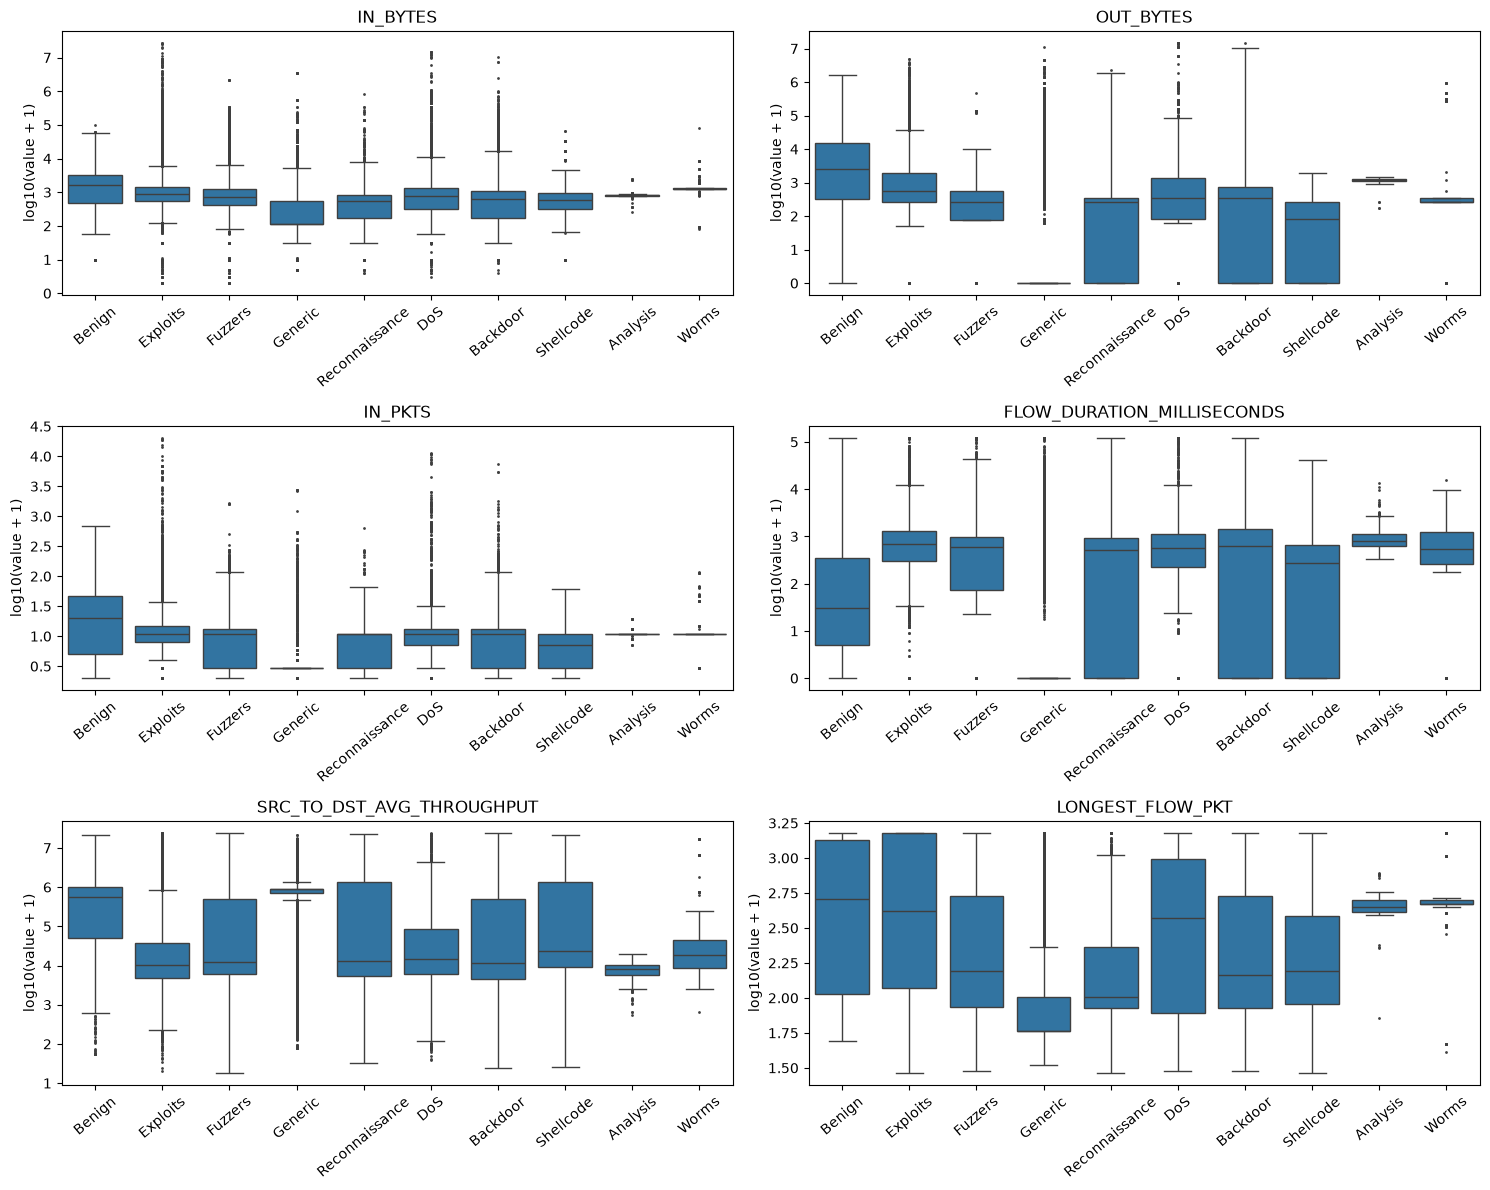

In [42]:
rank = pd.Series(np.random.default_rng(42).random(len(df)), index=df.index).groupby(df["Attack"]).rank()
sample = df[rank <= 20_000]
order = df["Attack"].value_counts().index

key_features = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "FLOW_DURATION_MILLISECONDS", "SRC_TO_DST_AVG_THROUGHPUT", "LONGEST_FLOW_PKT"]
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, col in zip(axes.flat, key_features):
    sns.boxplot(x=sample["Attack"], y=np.log10(sample[col] + 1), order=order, ax=ax, fliersize=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("log10(value + 1)")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

### 6.3 Physical limits
An extreme value is an error only if it is impossible on a real network.

In [43]:
pd.DataFrame({
    "maximum": [df["LONGEST_FLOW_PKT"].max(), df["FLOW_DURATION_MILLISECONDS"].max() / 1000,
                df["SRC_TO_DST_AVG_THROUGHPUT"].max() / 1e6, df["IN_BYTES"].max() / 1e6, df["DNS_TTL_ANSWER"].max() / (3600 * 24 * 365)],
    "limit": ["1514 bytes (Ethernet frame)", "~120 s (exporter splits longer flows)", "link speed (100 Mbps / 1 Gbps)",
              "none", "2^31-1 s = 68 years (RFC 2181)"],
}, index=["longest packet (bytes)", "longest flow (s)", "highest throughput (Mbps)", "largest flow (MB)", "largest DNS TTL (years)"])

,maximum,limit
longest packet (bytes),1508.000000,1514 bytes (Ethernet frame)
longest flow (s),120.948000,~120 s (exporter splits longer flows)
highest throughput (Mbps),36.000000,link speed (100 Mbps / 1 Gbps)
largest flow (MB),27.020934,none
largest DNS TTL (years),135.824401,2^31-1 s = 68 years (RFC 2181)


### 6.4 Skewness

In [44]:
df[measures].replace([np.inf, -np.inf], np.nan).skew().sort_values(ascending=False).head(10).round(1)

DST_TO_SRC_IAT_MIN           500.5
DNS_TTL_ANSWER               387.2
RETRANSMITTED_IN_BYTES       205.1
IN_BYTES                     204.5
RETRANSMITTED_IN_PKTS        182.2
NUM_PKTS_256_TO_512_BYTES    145.2
DST_TO_SRC_IAT_AVG           110.8
SRC_TO_DST_IAT_MIN            59.5
IN_PKTS                       57.7
SRC_TO_DST_IAT_STDDEV         56.1
dtype: float64

### Step 6 — Findings
- **The IQR rule flags 5–24% of all flows in most columns.** Network traffic is extremely skewed (skewness up to 500), so most "outliers" are the long tail of normal traffic. The IQR rule alone is not suitable here.
- **Where the outliers are depends on the feature:**
  - **Volume and throughput:** extremes are mostly Benign (large downloads).
  - **Packet size, inter-arrival time and TTL:** extremes are mostly attacks. 97–100% of attack flows are IQR outliers in `SHORTEST_FLOW_PKT`, `MIN_TTL` and `MAX_TTL`. They are the attack's signature, not errors (TTL is examined in 7.5).
- **Physical limits are respected:**
  - no packet is above 1514 bytes;
  - the longest flow is about 121 s, the exporter's timeout;
  - the highest throughput is 36 Mbps.
- **The only impossible extreme** is `DNS_TTL_ANSWER` above 2^31−1 (12 flows, see Step 4).

## Step 7 — Feature usefulness
- Constant or near-constant columns
- Identifier columns
- Leakage between target columns

### 7.1 Constant or near-constant columns

In [45]:
top_share = df.apply(lambda c: c.value_counts(normalize=True).iloc[0])
(100 * top_share[top_share > 0.99]).round(2).rename("% of flows with the most common value")

SRC_TO_DST_IAT_MIN    99.94
DST_TO_SRC_IAT_MIN    99.99
Name: % of flows with the most common value, dtype: float64

### 7.2 Identifier columns: do the IP addresses reveal the label?

In [46]:
by_ip = pd.crosstab(df["IPV4_SRC_ADDR"], df["Attack"] != "Benign").rename(columns={False: "benign flows", True: "attack flows"})
print("source IPs with only attacks:", (by_ip["benign flows"] == 0).sum(),
      "| only benign:", (by_ip["attack flows"] == 0).sum(),
      "| both:", ((by_ip["benign flows"] > 0) & (by_ip["attack flows"] > 0)).sum())
by_ip.sort_values("attack flows", ascending=False).head(6)

source IPs with only attacks: 4 | only benign: 36 | both: 0


Attack,benign flows,attack flows
IPV4_SRC_ADDR,,
175.45.176.1,0,35176
175.45.176.3,0,33820
175.45.176.0,0,31442
175.45.176.2,0,27255
10.40.182.1,642,0
10.40.182.6,58,0


### 7.3 Do the timestamps reveal the label?

In [47]:
hour = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms").dt.floor("h")
per_hour = pd.crosstab(hour, df["Label"]).rename(columns={0: "benign", 1: "attack"})
print(f"hours with traffic: {len(per_hour)}, hours with attacks: {(per_hour['attack'] > 0).sum()}")
per_hour

hours with traffic: 27, hours with attacks: 16


Label,benign,attack
FLOW_START_MILLISECONDS,,
2015-01-22 11:00:00,16412,1431
2015-01-22 12:00:00,87595,9054
2015-01-22 13:00:00,89453,6977
2015-01-22 14:00:00,90933,0
2015-01-22 15:00:00,84839,0
2015-01-22 16:00:00,90840,0
2015-01-22 17:00:00,90450,0
2015-01-22 18:00:00,89087,0
2015-01-22 19:00:00,71022,0


### 7.4 Redundant columns
Pairs with an absolute correlation above 0.98, plus columns that can be computed exactly from others.

In [48]:
corr = df[measures + ["TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE"]].replace([np.inf, -np.inf], np.nan).corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print(pairs[pairs > 0.98].sort_values(ascending=False).round(4).to_string())
print()
print("TCP_FLAGS == CLIENT_TCP_FLAGS | SERVER_TCP_FLAGS:", (df["TCP_FLAGS"] == (df["CLIENT_TCP_FLAGS"] | df["SERVER_TCP_FLAGS"])).mean())
print("ICMP_IPV4_TYPE == ICMP_TYPE // 256:             ", (df["ICMP_IPV4_TYPE"] == df["ICMP_TYPE"] // 256).mean())

LONGEST_FLOW_PKT            MAX_IP_PKT_LEN               1.0000
ICMP_TYPE                   ICMP_IPV4_TYPE               1.0000
OUT_BYTES                   RETRANSMITTED_OUT_BYTES      1.0000
MIN_TTL                     MAX_TTL                      0.9999
FLOW_DURATION_MILLISECONDS  DURATION_IN                  0.9996
IN_BYTES                    RETRANSMITTED_IN_BYTES       0.9992
SRC_TO_DST_SECOND_BYTES     DST_TO_SRC_AVG_THROUGHPUT    0.9957
OUT_BYTES                   RETRANSMITTED_OUT_PKTS       0.9917
TCP_FLAGS                   CLIENT_TCP_FLAGS             0.9913
RETRANSMITTED_OUT_BYTES     RETRANSMITTED_OUT_PKTS       0.9912
OUT_PKTS                    RETRANSMITTED_OUT_PKTS       0.9912
TCP_FLAGS                   SERVER_TCP_FLAGS             0.9866
DST_TO_SRC_SECOND_BYTES     SRC_TO_DST_AVG_THROUGHPUT    0.9820

TCP_FLAGS == CLIENT_TCP_FLAGS | SERVER_TCP_FLAGS: 1.0
ICMP_IPV4_TYPE == ICMP_TYPE // 256:              1.0


### 7.5 Does the TTL reveal the label?
The TTL depends on the operating system of the sending machine and on its distance in the network. Step 6
showed that every attack flow is a TTL "outlier".

In [49]:
ttl_table = pd.crosstab(df["MAX_TTL"], df["Label"]).rename(columns={0: "benign", 1: "attack"})
print(ttl_table[ttl_table.sum(axis=1) > 500])

attack_only_ttl = ttl_table.index[ttl_table["benign"] == 0]
benign_only_ttl = ttl_table.index[ttl_table["attack"] == 0]
print(f"\nflows with a TTL never seen in benign traffic: {df['MAX_TTL'].isin(attack_only_ttl).sum():,} (all attacks)")
print(f"flows with a TTL never seen in attack traffic: {df['MAX_TTL'].isin(benign_only_ttl).sum():,} (all benign)")

Label     benign  attack
MAX_TTL                 
0          26951     196
1           1276       0
30          3433       0
31        340310       0
32       1864712       0
63           231   31404
254            6   35626
255            0   60189

flows with a TTL never seen in benign traffic: 60,467 (all attacks)
flows with a TTL never seen in attack traffic: 2,210,543 (all benign)


### Step 7 — Findings
- **Near-constant columns:** `SRC_TO_DST_IAT_MIN` (99.94% the same value) and `DST_TO_SRC_IAT_MIN` (99.99%) carry almost no information.
- **IP addresses leak the label:**
  - 4 source IPs (175.45.176.0–3) send **only** attacks, and **all** the attacks;
  - the other 36 send only benign traffic.
  A model would simply learn the attacker's address, which is useless on another network.
- **TTL leaks the label:**
  - Benign traffic uses TTL 31/32; attacks use 63, 254 and 255.
  - 2,210,543 flows have a TTL that never appears in an attack, and 60,467 have one that never appears in benign traffic.
  This is a fingerprint of the lab's attacker machines, not of the attack.
- **Timestamps leak the label:** attacks happen only in specific hours of the capture.
- **No behavioural meaning:** `L4_SRC_PORT` (random client port) and `DNS_QUERY_ID` (random transaction number).
- **Exact copies:**
  - `TCP_FLAGS` = `CLIENT_TCP_FLAGS` OR `SERVER_TCP_FLAGS`;
  - `ICMP_IPV4_TYPE` = `ICMP_TYPE` ÷ 256;
  - `MAX_IP_PKT_LEN` = `LONGEST_FLOW_PKT`;
  - `MIN_IP_PKT_LEN` = `SHORTEST_FLOW_PKT` (apart from its error).
- **Very high correlations (> 0.99):** `MIN_TTL`/`MAX_TTL`, `FLOW_DURATION_MILLISECONDS`/`DURATION_IN`, and bytes/retransmitted bytes.

## Step 8 — Decisions

Decisions only: **nothing is changed in the data in this notebook.** Decisions that remove or change columns
must be identical for the four NetFlow datasets (they are merged later), so they are proposed to the team and
recorded in `docs/decision_log.md` before they are applied.

| # | Check that found it | Problem | Columns / labels | Size | Decision | Reason |
|---|---|---|---|---|---|---|
| 1 | 1.4 class distribution | Strong class imbalance | `Attack` | Benign 94.6% (17.5 : 1) | Delete nothing now. The shared sampling rule (max 200k per label) reduces Benign later. Evaluate models with macro-F1 and per-class recall, not accuracy. | A model that always answers "Benign" would already reach 94.6% accuracy. |
| 2 | 1.4 class distribution | Very rare class | Worms | 158 flows (0.007%) | Keep all of them. Also report results at family level (*Malware and botnets* = 4,817 flows). | It is real attack data; at label level it is too small to learn reliably. |
| 3 | 1.3 taxonomy mapping | Only 6 of the 9 families present | Credential, Web/injection, Interception, Data theft | 4 families missing | No change. Documented: these families must come from the other datasets. | Limits what UNSW alone can teach (SQ2, SQ3). |
| 4 | 1.2 `Label` vs `Attack` | Two target columns | `Label`, `Attack` | 0 disagreements | Keep both as targets; never use one as a feature for the other. | Leakage. |
| 5 | 2.2 timestamp conversion | Timestamps stored as integers | `FLOW_START_MILLISECONDS`, `FLOW_END_MILLISECONDS` | 2 columns | Convert to datetime for analysis only; not model features (see 26). | Milliseconds since 1970 are not readable dates. |
| 6 | 2.3 code columns | Codes stored as numbers | ports, `PROTOCOL`, `L7_PROTO`, 3 TCP flag columns, 2 ICMP columns, `DNS_QUERY_TYPE`, `FTP_COMMAND_RET_CODE` | 11 columns | Treat as categorical. The encoding (e.g. port ranges 0–1023 / 1024–49151 / 49152–65535) is decided in feature engineering. | Averages and distances between codes have no meaning. |
| 7 | 2.4 `L7_PROTO` decimals + raw CSV text | Float holding two codes; trailing zeros already lost | `L7_PROTO` | 23,866 flows with a sub-code, 10 ambiguous | Split into main protocol (before the dot) and sub-protocol (after the dot, 0 if none). The 10 ambiguous flows are documented. | The main protocol is always reliable; `7.5` vs `7.50` cannot be recovered. |
| 8 | 2.5 invalid codes | Unassigned protocol numbers, port 0, invalid DNS/ICMP types | `PROTOCOL`, ports, `DNS_QUERY_TYPE`, `ICMP_IPV4_TYPE` | 754 + 6 + 6 + 6 flows, **all attacks** | Keep. | They are attack behaviour (fuzzing, malformed packets), not recording errors. |
| 9 | 3.1–3.3 NaN/inf + cause | NaN and inf from division by a duration of 0 | `SRC_TO_DST_SECOND_BYTES`, `DST_TO_SRC_SECOND_BYTES` | 63,425 NaN + 59,068 inf; 122,493 inf | **Drop both columns** (do not drop rows, do not impute). | See 10 and 11. `SRC_TO_DST_AVG_THROUGHPUT` / `DST_TO_SRC_AVG_THROUGHPUT` carry the same information correctly (correlation > 0.98, no inf). |
| 10 | 3.3 formula check | Columns mislabelled: direction swapped and unit is bytes per **millisecond** | same 2 columns | 100% of flows | Covered by 9. Reported as a documentation error. | A feature whose meaning is wrong cannot be interpreted. |
| 11 | 3.4 missingness per class | Missingness depends on the class | same 2 columns | 75.8% of Generic, 3.9% of Benign | Covered by 9. **Team note:** `clean()` in `config.py` drops every row with NaN, so these columns must be dropped *before* `clean()` is called. | Dropping rows would delete most of the Generic class. |
| 12 | 3.6 disguised missing | ICMP fields filled for non-ICMP flows | `ICMP_TYPE`, `ICMP_IPV4_TYPE` | 1,754,341 TCP flows | Set both to 0 for every flow that is not ICMP (`PROTOCOL` ≠ 1). | ICMP types have no meaning outside ICMP; a model would learn a recording artefact. |
| 13 | 3.6 disguised missing + 4.2 | TTL = 0 means "not recorded" | `MIN_TTL`, `MAX_TTL` | 27,147 flows (99% UDP, 99% Benign) | Keep the rows and the value 0 as the "unknown" marker; no imputation. Check in the EDA whether it separates Benign artificially. | TTL depends on the sending machine, so it cannot be guessed; 196 of these flows are attacks. |
| 14 | 3.6 disguised missing | 0 = "does not apply" in protocol-specific fields | DNS fields, `FTP_COMMAND_RET_CODE` | 0 outside their protocol; 112 DNS flows without a query type, 13,994 without an answer TTL, 43,911 FTP flows without a reply code | Keep 0 as "not applicable / no reply". No imputation. | Consistent with the protocol; nothing is missing. |
| 15 | 4.2 rules + 4.3 | `MIN_IP_PKT_LEN` = 0 (impossible); both columns copy the `FLOW_PKT` ones | `MIN_IP_PKT_LEN`, `MAX_IP_PKT_LEN` | 66,121 one-way flows wrong | **Drop both columns**; keep `SHORTEST_FLOW_PKT` and `LONGEST_FLOW_PKT`. | Exact copies, and the copy is the one with errors. |
| 16 | 4.2 rules + 4.3 | Impossible byte count (about 9 bytes for a TCP packet) | `IN_BYTES` | 45,540 flows (1.9%, 94% Benign) | Keep the rows; document as an exporter error. Re-check in the EDA. | The true value cannot be recovered; removing them changes little for Benign but removes 2,579 attack flows. |
| 17 | 4.2 rules + 4.3 | Size-bin counts 1–13 higher than the packet counts | `NUM_PKTS_*` (5 columns) | 482,792 flows (20%) | Keep; document as a measurement inconsistency. | Too common to remove, and we cannot tell which counter is right. |
| 18 | 4.2 rules | Largest inter-arrival gap longer than the flow | `SRC_TO_DST_IAT_MAX` | 33,970 flows (1.4%) | Keep; document. | Small timing inconsistency of the exporter; the value cannot be corrected. |
| 19 | 4.2 rules + 6.3 limits | DNS TTL above 2^31−1 (invalid) | `DNS_TTL_ANSWER` | 12 flows (+270 above 7 days) | Set the 12 invalid values to 0, as RFC 2181 prescribes. Keep the 270 allowed but large ones. | The standard defines how invalid TTLs are treated. |
| 20 | 4.2 rules | End − start differs from the duration by 1 ms | timestamps, `FLOW_DURATION_MILLISECONDS` | at most 1 ms (0 flows above 1 ms) | No action. | Rounding, not an error. |
| 21 | 4.2 rules | TCP flow without any TCP flag | `TCP_FLAGS` | 7 flows | Keep. | Negligible. |
| 22 | 5.1 exact duplicates | Exact duplicate rows | all | 14,815 rows (0.63%), 14,801 Benign | Remove, keeping the first occurrence (shared `clean()` rule). | Duplicates add no information and could leak between train and test. |
| 23 | 5.3 flow key | No unique flow identifier | 5-tuple + start time | 483,517 non-duplicate rows share a key | No action; do not deduplicate on this key. | The exporter splits flows; rows sharing a key are different flows. |
| 24 | 5.4 behaviour duplicates | Same behaviour, different attack label | `Attack` | 30,907 rows in 993 groups, never Benign vs attack | Keep; document as label noise between attack types. Report label-level and family-level results separately. | We cannot know which label is right; the binary task is not affected. |
| 25 | 6.1 IQR / z-score + 6.2 box plots | IQR flags 5–24% of flows in most columns | measurement columns | heavy tails, skewness up to 500 | Keep all statistical outliers. Use a log transform in feature engineering. | Extremes are attack behaviour or normal long-tail traffic; no physical limit is broken (6.3). |
| 26 | 7.2 IP vs label + 7.3 time vs label | Identifiers and time reveal the label | `IPV4_SRC_ADDR`, `IPV4_DST_ADDR`, timestamps | 4 IPs send all attacks | Not used as model features (IPs are already dropped by `clean()`). | The model would learn "who/when" instead of "how", which does not transfer to a new network (SQ3). |
| 27 | 6.1 IQR per class + 7.5 TTL vs label | TTL reveals the label (host fingerprint) | `MIN_TTL`, `MAX_TTL` | benign 31/32, attacks 63/254/255; 60,467 flows have attack-only TTLs | Not used as model features. Checked again on the other datasets; the team decides together for the merged data. | It identifies the attacker machines of this lab, not the attack; it would not transfer to an unseen network (SQ3). |
| 28 | 7.1 + 2.3 | Random identifiers without behavioural meaning | `L4_SRC_PORT`, `DNS_QUERY_ID` | 2 columns | Not used as model features. | Random numbers chosen by the client. |
| 29 | 7.1 near-constant | Near-constant columns | `SRC_TO_DST_IAT_MIN`, `DST_TO_SRC_IAT_MIN` | 99.94% / 99.99% one value | ~~Drop.~~ **Revised after CIC18 (02_cic18 #38):** decide in feature selection with all datasets. | Near-constant here, but informative in CIC18, so it must not be removed from the merged data because of UNSW alone. |
| 30 | 7.4 redundancy | Exact copies of other columns | `TCP_FLAGS`, `ICMP_IPV4_TYPE` | 2 columns | Drop (they can be recomputed from the others). | No extra information. |
| 31 | 7.4 correlation | Very high correlations (> 0.99) | `MIN_TTL`/`MAX_TTL`, duration columns, bytes/retransmitted bytes | several pairs | Decide in feature selection (phase 5) with one rule for the whole team. | Highly correlated is not the same as identical; the choice should use all datasets. |
| 32 | 0.3 feature dictionary | Errors in the official feature document | IAT descriptions, `DURATION_OUT`, `..._SECOND_BYTES` | documentation | Report them; use our corrected descriptions. | Shows why the data must be checked, not trusted. |
| 33 | 4.4 *new* | IAT average below IAT minimum | `..._IAT_AVG`, `..._IAT_MIN` | 316 flows | Keep; read `IAT_MIN` as smallest non-zero gap | Exporter convention: 0-ms gaps are skipped by the minimum but counted in the average |
| 34 | 4.4 *new* | TCP window 0 although packets were sent | `TCP_WIN_MAX_IN/OUT` | 45,884 flows | Keep | UNSW: client-side zeros without reset, unexplained; a reset carries window 0 by design |
| 35 | 4.4 *new* | Exceptions to the one-way `MIN_IP_PKT_LEN` pattern; 1-packet flow longer than `IN_BYTES` | `MIN_IP_PKT_LEN`, `LONGEST_FLOW_PKT`, `IN_BYTES` | 0 / 0 flows | Keep; columns dropped anyway (M7) | Too few to matter |


**Update after the ToN-IoT / BoT-IoT cross-check (Cyrine Chabbar).** Rows marked *new* come from section 4.4. The "200k per label" sampling mentioned in older rows is replaced by the plan in section 6 of `report/data_problems/phase2_data_problems.pdf`: one row per different behaviour (with a `count` column), class and network weights, a grouped 80/20 split and realistic 95/5 test sets. Pending team agreement.